In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [17]:
df = pd.read_csv("BIED_Smart_Agriculture_Dataset.csv")
df.head()

,timestamp,device_id,location,crop_type,season,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,crop_health,yield_estimate,pest_risk,anomaly_flag
0,2024-01-01 00:00:00,BD-MYM-002,Mymensingh,Rice,winter,23.16,59.08,0.00,41.64,6.63,16.0,61.58,0,Healthy,4.29,Low,0
1,2024-01-01 00:00:00,BD-MYM-005,Mymensingh,Wheat,winter,23.79,56.87,0.00,57.24,6.57,52.0,11.52,0,Healthy,3.25,Low,0
2,2024-01-01 00:00:00,BD-RAJ-003,Rajshahi,Rice,winter,19.64,62.09,0.00,51.01,5.64,79.0,31.35,0,Healthy,4.67,Low,0
3,2024-01-01 01:00:00,BD-MYM-002,Mymensingh,Tomato,winter,18.68,52.33,14.87,75.14,6.26,68.0,24.17,0,Healthy,35.56,Low,0
4,2024-01-01 01:00:00,BD-CHA-001,Chattogram,Rice,winter,20.75,59.96,0.00,64.59,6.01,31.0,85.57,0,Healthy,4.40,Low,0


## Часть 2. Предобработка данных

 Масштабирование одного признака

Применим 3 метода к признаку `soil_moisture` на обучающей выборке:
1. **StandardScaler** — делает среднее = 0, стандартное отклонение = 1.
2. **MinMaxScaler** — сжимает значения в диапазон [0, 1].
3. **RobustScaler** — использует медиану и IQR, устойчив к выбросам.

In [18]:
from sklearn.model_selection import train_test_split

# Отделяем признаки от цели и убираем идентификаторы
X = df.drop(columns=['crop_health', 'timestamp', 'device_id'])
y = df['crop_health']

# Разделение 80/20 со стратификацией по классам
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Размер train: {X_train.shape}")
print(f"Размер test:  {X_test.shape}")
print(f"\nПропорции классов в train:\n{y_train.value_counts(normalize=True).round(4)*100}")
print(f"\nПропорции классов в test:\n{y_test.value_counts(normalize=True).round(4)*100}")

Размер train: (8000, 14)
Размер test:  (2000, 14)

Пропорции классов в train:
crop_health
Healthy     74.19
Stressed    20.34
Critical     5.48
Name: proportion, dtype: float64

Пропорции классов в test:
crop_health
Healthy     74.15
Stressed    20.35
Critical     5.50
Name: proportion, dtype: float64


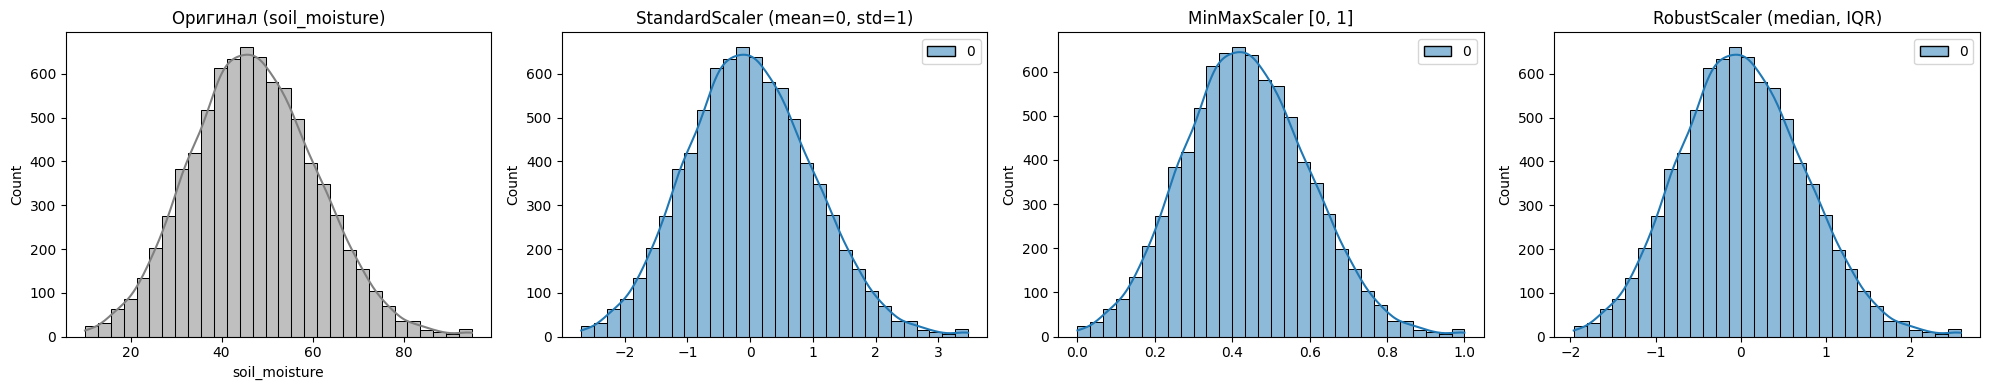

In [5]:
col = 'soil_moisture'
data_original = X_train[[col]].copy()

# Применяем скейлеры (fit на train)
data_standard = StandardScaler().fit_transform(data_original)
data_minmax = MinMaxScaler().fit_transform(data_original)
data_robust = RobustScaler().fit_transform(data_original)

# Построение графиков
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

sns.histplot(data_original[col], bins=30, kde=True, ax=axes[0], color='gray')
axes[0].set_title('Оригинал (soil_moisture)')

sns.histplot(data_standard, bins=30, kde=True, ax=axes[1], color='blue')
axes[1].set_title('StandardScaler (mean=0, std=1)')

sns.histplot(data_minmax, bins=30, kde=True, ax=axes[2], color='green')
axes[2].set_title('MinMaxScaler [0, 1]')

sns.histplot(data_robust, bins=30, kde=True, ax=axes[3], color='red')
axes[3].set_title('RobustScaler (median, IQR)')

plt.tight_layout()
plt.show()

### Вывод по результатам масштабирования признака `soil_moisture`

Анализ графиков показал, что все три метода изменили масштаб признака, но **не изменили форму его распределения** (она осталась нормальной, колоколообразной). Это ожидаемо, так как скейлеры — это линейные преобразования.

1. **StandardScaler** отцентрировал данные (среднее стало 0, стандартное отклонение 1).
2. **MinMaxScaler** сжал данные в жесткий диапазон [0, 1].
3. **RobustScaler** отцентрировал данные по медиане (0).

**Итоговый выбор:**
Для дальнейшей предобработки всех числовых признаков (включая `soil_moisture`) мы выбираем **RobustScaler**. Поскольку ранее в данных были обнаружены выбросы (в `humidity`, `soil_moisture` и др.), RobustScaler обеспечит наиболее устойчивое и корректное масштабирование, не искажая основную массу данных экстремальными значениями.

### Предобработка всех оставшихся столбцов (Train/Test)

После разделения выборки (80/20) необходимо привести все признаки к единому формату, пригодному для ML-моделей.

**Обоснование выбора методов:**
1. **Числовые признаки** (`temperature`, `humidity`, `rainfall`, `soil_moisture`, `soil_ph`, `light_intensity`, `fertilizer_used`, `yield_estimate`):
   Применяем **`RobustScaler`**. Как было показано ранее на графиках, в данных присутствуют выбросы . RobustScaler использует медиану и межквартильный размах (IQR), поэтому он не искажает масштаб основной массы данных из-за экстремальных значений (в отличие от MinMax или Standard).
   
2. **Категориальные признаки** (`crop_type`, `season`, `location`, `pest_risk`):
   Применяем **One-Hot Encoding** (`pd.get_dummies`). Это признаки, не имеющие строгого порядка (номинальные). Кодирование в 0 и 1 позволяет моделям корректно их обрабатывать. Параметр `drop_first=True` убирает «ловушку фиктивных переменных».
   
3. **Целевая переменная** (`crop_health`):
   Применяем **LabelEncoder**. Модели требуют числовые метки классов (0, 1, 2) вместо строк ("Healthy", "Stressed", "Critical").


In [19]:
num_cols = ['temperature', 'humidity', 'rainfall', 'soil_moisture', 'soil_ph',
            'light_intensity', 'fertilizer_used', 'irrigation_needed',
            'yield_estimate', 'anomaly_flag']

cat_cols = ['location', 'crop_type', 'season', 'pest_risk']

print("Числовые признаки:", num_cols)
print("Категориальные признаки:", cat_cols)
print("-" * 50)

# масштабирование числовых признаков
# fit только на train, transform на test
scaler = RobustScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
print(" Числовые признаки масштабированы (RobustScaler)")

# кодирование категориальных признаков (One-Hot Encoding)
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)
print(" Категориальные признаки закодированы (One-Hot Encoding)")

# кодирование целевой переменной
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
print(" Целевая переменная закодирована (LabelEncoder)")

print("-" * 50)
print(f"Итоговая форма X_train: {X_train.shape}")
print(f"Итоговая форма X_test:  {X_test.shape}")
print(f"Классы: {le.classes_}")

Числовые признаки: ['temperature', 'humidity', 'rainfall', 'soil_moisture', 'soil_ph', 'light_intensity', 'fertilizer_used', 'irrigation_needed', 'yield_estimate', 'anomaly_flag']
Категориальные признаки: ['location', 'crop_type', 'season', 'pest_risk']
--------------------------------------------------
 Числовые признаки масштабированы (RobustScaler)
 Категориальные признаки закодированы (One-Hot Encoding)
 Целевая переменная закодирована (LabelEncoder)
--------------------------------------------------
Итоговая форма X_train: (8000, 21)
Итоговая форма X_test:  (2000, 21)
Классы: ['Critical' 'Healthy' 'Stressed']


In [22]:
X_train.head()

,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,yield_estimate,anomaly_flag,...,location_Khulna,location_Mymensingh,location_Rajshahi,location_Sylhet,crop_type_Potato,crop_type_Rice,crop_type_Tomato,crop_type_Wheat,season_winter,pest_risk_Medium
8616,0.093418,-0.038589,0.00,-0.005617,-0.222222,-0.001764,-0.923190,0.0,-0.070125,0.0,...,False,False,False,True,False,False,False,False,False,False
8096,0.329087,0.990464,0.00,-0.388659,-0.236111,0.345573,0.249541,0.0,0.939055,0.0,...,False,False,False,False,True,False,False,False,False,True
5115,0.598726,0.974495,5.67,-0.038251,0.444444,-0.003337,0.348401,0.0,-0.089592,0.0,...,False,True,False,False,False,False,False,False,False,True
5019,0.428875,1.275227,0.00,-0.503678,0.430556,0.431688,-1.094451,0.0,1.429267,0.0,...,False,False,False,False,False,False,True,False,False,True
7345,0.233546,0.122865,0.00,-0.651331,0.916667,-0.002110,0.044101,1.0,1.138591,0.0,...,False,False,False,False,False,False,True,False,False,False
